# Exercise 7: Cost-Minimized Unrestricted Classification
**Team:** Swiss Quant Industrial

Dave's new server removes the three-feature PLC constraint. This notebook trains an unrestricted XGBoost model, tunes the operating threshold using the Exercise 6 CHF cost metric, and compares the result with the Exercise 5 PLC rule.

Labels use the final project convention: `0 = BAD`, `1 = GOOD`.


In [1]:
from pathlib import Path
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 180)

BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR_150825 = BASE_DIR / "data" / "DataDump_150825"
DATA_DIR_300825 = BASE_DIR / "data" / "DataDump_300825"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}
RAW_TO_SEMANTIC_LABEL = {0: GOOD_CLASS, 1: BAD_CLASS}
BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10

def feature_columns(df):
    return sorted([c for c in df.columns if c.startswith("feature_")], key=lambda c: int(c.split("_")[1]))

def standardize_manual_label(df, label_col="Manual_Label", raw_label_col="Manual_Label_Raw"):
    out = df.copy()
    raw = pd.to_numeric(out[label_col], errors="coerce")
    out[raw_label_col] = raw
    out[label_col] = raw.map(RAW_TO_SEMANTIC_LABEL).astype("Int64")
    return out

def add_label_name(df, label_col="Manual_Label"):
    out = df.copy()
    out[f"{label_col}_Name"] = out[label_col].map(LABEL_NAMES)
    return out

def load_master_table():
    df = pd.read_csv(OUTPUT_DIR / "exercise3_master_table_case_level.csv")
    if "Manual_Label" in df.columns:
        df["Manual_Label"] = pd.to_numeric(df["Manual_Label"], errors="coerce").astype("Int64")
    return df

def load_logbook_events():
    return pd.read_csv(OUTPUT_DIR / "logbook_events_structured.csv")

def load_heatwave_table():
    sensor = pd.read_csv(DATA_DIR_300825 / "sensor_data_august_shift.csv")
    quality = pd.read_csv(DATA_DIR_300825 / "quality_labels_august_shift.csv")
    production = pd.read_csv(DATA_DIR_300825 / "production_log_august_shift.csv", parse_dates=["Timestamp"])
    if len(sensor) != len(production):
        raise ValueError("Heatwave sensor and production logs should be row-aligned and equal length.")
    if not sensor["Charge_ID"].reset_index(drop=True).eq(production["Charge_ID"].reset_index(drop=True)).all():
        raise ValueError("Heatwave production rows are not row-aligned with sensor Charge_ID values.")
    table = sensor.merge(quality[["Case_ID", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="inner")
    if len(table) != len(sensor):
        raise ValueError("Heatwave quality merge changed row count; expected one label per Case_ID.")
    table = pd.concat([table.reset_index(drop=True), production.reset_index(drop=True)[["Timestamp", "Operator_ID"]]], axis=1)
    table = standardize_manual_label(table)
    table["label_available"] = table["Manual_Label"].notna()
    ts = pd.to_datetime(table["Timestamp"], errors="coerce")
    table["production_date"] = ts.dt.date
    table["production_hour"] = ts.dt.hour + ts.dt.minute / 60
    return add_label_name(table)

def _present_columns(df, cols):
    return [c for c in cols if c in df.columns]

def add_urs_rhythm_features(df, reference_df=None, source_features=("feature_2", "feature_4", "feature_5"), window=25):
    out = df.copy()
    signals = _present_columns(out, source_features)
    if not signals:
        raise ValueError("None of the rhythm source features are present.")
    reference = reference_df if reference_df is not None else out
    ref_numeric = reference[signals].apply(pd.to_numeric, errors="coerce")
    medians = ref_numeric.median()
    scales = ref_numeric.std().replace(0, np.nan).fillna(1.0)
    numeric = out[signals].apply(pd.to_numeric, errors="coerce").fillna(medians)
    standardized = (numeric - medians) / scales
    sort_cols = _present_columns(out, ["Timestamp_fixed", "Timestamp", "Charge_ID", "Case_ID"])
    ordered_index = out.sort_values(sort_cols).index if sort_cols else out.index
    ordered = standardized.loc[ordered_index]
    local_change = ordered.diff().abs().mean(axis=1).fillna(0.0)
    rolling_volatility = ordered.rolling(window=window, min_periods=3).std().mean(axis=1).fillna(0.0)
    rhythm = 0.4 * local_change + 0.6 * rolling_volatility
    out["Urs_Local_Signal_Change"] = local_change.reindex(out.index).astype(float)
    out["Urs_Rolling_Signal_Volatility"] = rolling_volatility.reindex(out.index).astype(float)
    out["Urs_Rhythm_Index"] = rhythm.reindex(out.index).astype(float)
    return out

def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }

def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return counts["bad_shipped"] * BAD_SHIPPED_COST_CHF + counts["good_wasted"] * GOOD_WASTED_COST_CHF

def classification_summary(y_true, y_pred, model, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    return {
        "model": model,
        "threshold": threshold,
        "rows": len(y_true),
        **counts,
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": production_cost_chf(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

def predict_from_bad_probability(prob_bad, threshold):
    return pd.Series(np.where(np.asarray(prob_bad) >= threshold, BAD_CLASS, GOOD_CLASS))


## 1. Load Linked Inputs

This notebook is self-contained except for outputs created by earlier coding notebooks: Exercise 3 provides the semantic master table, Exercise 4 provides `Urs_Rhythm_Index`, and Exercise 5 provides out-of-fold PLC predictions for a fair baseline comparison.


In [2]:
master = load_master_table()
engineered = pd.read_csv(OUTPUT_DIR / "exercise4_engineered_features.csv")
plc_predictions = pd.read_csv(OUTPUT_DIR / "exercise5_plc_predictions.csv")

engineered_cols = ["Case_ID", "Urs_Local_Signal_Change", "Urs_Rolling_Signal_Volatility", "Urs_Rhythm_Index"]
model_df = master.merge(engineered[engineered_cols], on="Case_ID", how="left")
model_df = model_df.dropna(subset=["Manual_Label"]).copy()
model_df["Manual_Label"] = model_df["Manual_Label"].astype(int)
base_features = feature_columns(model_df)
engineered_features = ["Urs_Local_Signal_Change", "Urs_Rolling_Signal_Volatility", "Urs_Rhythm_Index"]
model_features = base_features + engineered_features
X = model_df[model_features].apply(pd.to_numeric, errors="coerce")
y = model_df["Manual_Label"]

display(pd.DataFrame([
    {"input": "Exercise 3 master rows", "rows": len(master)},
    {"input": "Exercise 4 engineered rows", "rows": len(engineered)},
    {"input": "Exercise 5 PLC prediction rows", "rows": len(plc_predictions)},
    {"input": "labeled modeling rows", "rows": len(model_df)},
    {"input": "model feature count", "rows": len(model_features)},
]))
display(y.map(LABEL_NAMES).value_counts().rename_axis("quality").reset_index(name="rows"))


,input,rows
0,Exercise 3 master rows,2006
1,Exercise 4 engineered rows,1404
2,Exercise 5 PLC prediction rows,1404
3,labeled modeling rows,1404
4,model feature count,36


,quality,rows
0,BAD,722
1,GOOD,682


## 2. Train XGBoost and Tune the Production-Cost Threshold

The model estimates `P(BAD)`. A normal 0.50 threshold optimizes neither safety nor economics here. One `BAD -> GOOD` escape costs **500 CHF**, while one `GOOD -> BAD` false reject costs **10 CHF**. A bad escape is therefore as expensive as fifty good rejects.

The decision-theory break-even probability is approximately `10 / (500 + 10) = 1.96%`: if a case has more than about 2% bad risk, rejection can be economically rational. The validation set chooses the final threshold because model probabilities are not perfectly calibrated.


In [3]:
RANDOM_STATE = 42
X_train_full, X_test, y_train_full, y_test, idx_train_full, idx_test = train_test_split(X, y, model_df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE)

split_summary = pd.DataFrame([
    {"split": "train", "rows": len(y_train), "bad": int((y_train == BAD_CLASS).sum()), "good": int((y_train == GOOD_CLASS).sum())},
    {"split": "validation", "rows": len(y_val), "bad": int((y_val == BAD_CLASS).sum()), "good": int((y_val == GOOD_CLASS).sum())},
    {"split": "test", "rows": len(y_test), "bad": int((y_test == BAD_CLASS).sum()), "good": int((y_test == GOOD_CLASS).sum())},
])
display(split_summary)
display(Markdown(f"Cost metric: **{BAD_SHIPPED_COST_CHF} CHF** for BAD -> GOOD; **{GOOD_WASTED_COST_CHF} CHF** for GOOD -> BAD."))

xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85, min_child_weight=1, reg_lambda=1.0, scale_pos_weight=1.0, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)
xgb_model.fit(X_train, (y_train == BAD_CLASS).astype(int), verbose=False)

val_prob_bad = xgb_model.predict_proba(X_val)[:, 1]
test_prob_bad = xgb_model.predict_proba(X_test)[:, 1]
probability_quality = pd.DataFrame([
    {"split": "validation", "roc_auc_for_BAD": roc_auc_score((y_val == BAD_CLASS).astype(int), val_prob_bad), "average_precision_for_BAD": average_precision_score((y_val == BAD_CLASS).astype(int), val_prob_bad)},
    {"split": "test", "roc_auc_for_BAD": roc_auc_score((y_test == BAD_CLASS).astype(int), test_prob_bad), "average_precision_for_BAD": average_precision_score((y_test == BAD_CLASS).astype(int), test_prob_bad)},
])
display(probability_quality)


,split,rows,bad,good
0,train,842,433,409
1,validation,281,144,137
2,test,281,145,136


Cost metric: **500 CHF** for BAD -> GOOD; **10 CHF** for GOOD -> BAD.

,split,roc_auc_for_BAD,average_precision_for_BAD
0,validation,0.925081,0.920602
1,test,0.938032,0.941082


The validation-selected threshold is `0.049257`. This is low because the model is being used as a risk-control gate: the theoretical cost break-even is `0.0196`, and validation chooses the nearby threshold that minimizes realized CHF cost.

,threshold,cost_chf,bad_shipped,good_wasted,accuracy,recall_bad,recall_good
0,0.049257,1220,0,122,0.565836,1.0,0.109489
1,0.049204,1230,0,123,0.562278,1.0,0.102190
2,0.049000,1240,0,124,0.558719,1.0,0.094891
3,0.049026,1240,0,124,0.558719,1.0,0.094891
4,0.048408,1250,0,125,0.555160,1.0,0.087591
5,0.047000,1260,0,126,0.551601,1.0,0.080292
6,0.048000,1260,0,126,0.551601,1.0,0.080292
7,0.048387,1260,0,126,0.551601,1.0,0.080292
8,0.046906,1270,0,127,0.548043,1.0,0.072993
9,0.044000,1280,0,128,0.544484,1.0,0.065693


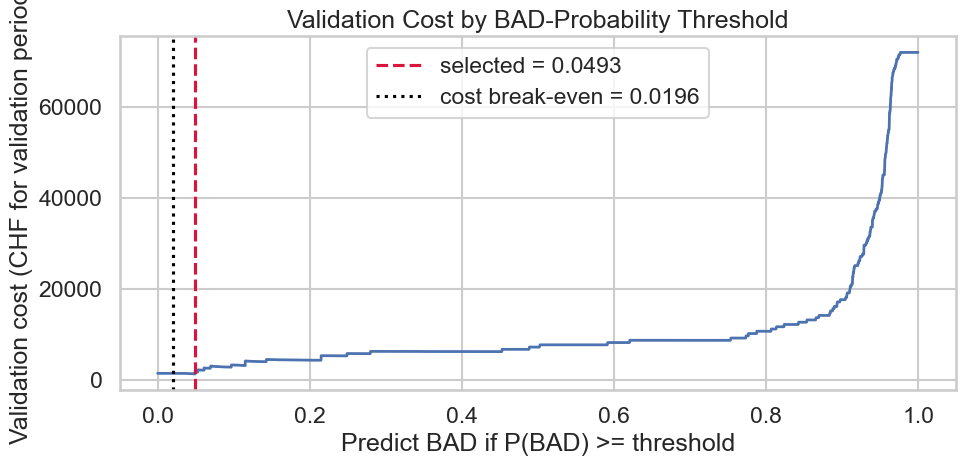

In [4]:
thresholds = np.unique(np.r_[np.linspace(0.0, 1.0, 1001), val_prob_bad])
threshold_rows = []
for threshold in thresholds:
    y_pred = predict_from_bad_probability(val_prob_bad, threshold)
    threshold_rows.append(classification_summary(y_val, y_pred, "threshold candidate", float(threshold)))
val_curve = pd.DataFrame(threshold_rows).sort_values(["cost_chf", "bad_shipped", "good_wasted", "threshold"]).reset_index(drop=True)
best_threshold = float(val_curve.loc[0, "threshold"])
breakeven_threshold = GOOD_WASTED_COST_CHF / (BAD_SHIPPED_COST_CHF + GOOD_WASTED_COST_CHF)

display(Markdown(
    f"The validation-selected threshold is `{best_threshold:.6f}`. This is low because the model is being used as a risk-control gate: "
    f"the theoretical cost break-even is `{breakeven_threshold:.4f}`, and validation chooses the nearby threshold that minimizes realized CHF cost."
))
display(val_curve.head(10)[["threshold", "cost_chf", "bad_shipped", "good_wasted", "accuracy", "recall_bad", "recall_good"]])

plot_curve = val_curve.sort_values("threshold")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(plot_curve["threshold"], plot_curve["cost_chf"], linewidth=2)
ax.axvline(best_threshold, color="crimson", linestyle="--", label=f"selected = {best_threshold:.4f}")
ax.axvline(breakeven_threshold, color="black", linestyle=":", label=f"cost break-even = {breakeven_threshold:.4f}")
ax.set_title("Validation Cost by BAD-Probability Threshold")
ax.set_xlabel("Predict BAD if P(BAD) >= threshold")
ax.set_ylabel("Validation cost (CHF for validation period)")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Compare Against the Exercise 5 PLC Rule

The comparison below is measured over the same held-out test period of 281 cases. To make the business impact comparable beyond the sample, the notebook also reports costs per 1,000 cases and scales the result to the observed early-August production volume in the master table.


In [5]:
y_pred_xgb_default = predict_from_bad_probability(test_prob_bad, 0.5)
y_pred_xgb_default.index = y_test.index
y_pred_xgb_cost = predict_from_bad_probability(test_prob_bad, best_threshold)
y_pred_xgb_cost.index = y_test.index

plc_required = {"row_index", "actual_label", "plc_pred_label", "selected_triplet", "operator_family"}
missing = plc_required - set(plc_predictions.columns)
if missing:
    raise ValueError(f"Exercise 5 prediction export is missing columns: {missing}")
plc_test = plc_predictions.set_index("row_index").loc[y_test.index]
y_pred_plc = plc_test["plc_pred_label"].astype(int)

consistency = pd.DataFrame([
    {"check": "Exercise 5 actual labels match semantic master labels", "status": bool((plc_test["actual_label"].astype(int) == y_test.astype(int)).all())},
    {"check": "selected_triplet", "status": plc_predictions["selected_triplet"].dropna().unique()[0]},
    {"check": "operator_family", "status": plc_predictions["operator_family"].dropna().unique()[0]},
])
display(consistency)

comparison = pd.DataFrame([
    classification_summary(y_test, y_pred_plc, "Exercise 5 PLC rule"),
    classification_summary(y_test, y_pred_xgb_default, "Exercise 7 XGBoost, default threshold", 0.5),
    classification_summary(y_test, y_pred_xgb_cost, "Exercise 7 XGBoost, cost-optimized", best_threshold),
])
plc_cost = float(comparison.loc[comparison["model"].eq("Exercise 5 PLC rule"), "cost_chf"].iloc[0])
comparison["cost_difference_vs_plc_chf"] = comparison["cost_chf"] - plc_cost
comparison["cost_reduction_vs_plc_pct"] = np.where(plc_cost > 0, (plc_cost - comparison["cost_chf"]) / plc_cost, np.nan)
comparison["cost_per_1000_cases_chf"] = comparison["cost_chf"] / len(y_test) * 1000

production_dates = pd.to_datetime(master["production_date"], errors="coerce")
observed_days = int(production_dates.dt.date.nunique())
observed_cases = int(master.shape[0])
comparison["estimated_cost_for_observed_early_august_period_chf"] = comparison["cost_chf"] / len(y_test) * observed_cases
comparison.to_csv(OUTPUT_DIR / "exercise7_model_comparison.csv", index=False)

display(comparison[["model", "threshold", "bad_shipped", "good_wasted", "cost_chf", "cost_per_1000_cases_chf", "estimated_cost_for_observed_early_august_period_chf", "cost_difference_vs_plc_chf", "cost_reduction_vs_plc_pct", "accuracy", "recall_bad", "recall_good"]])
display(Markdown(f"The time frame for the scaled estimate is the observed Exercise 3 production window: **{observed_cases:,} cases across {observed_days} production days**."))


,check,status
0,Exercise 5 actual labels match semantic master...,True
1,selected_triplet,"('feature_3', 'feature_10', 'feature_33')"
2,operator_family,raw_ratios


,model,threshold,bad_shipped,good_wasted,cost_chf,cost_per_1000_cases_chf,estimated_cost_for_observed_early_august_period_chf,cost_difference_vs_plc_chf,cost_reduction_vs_plc_pct,accuracy,recall_bad,recall_good
0,Exercise 5 PLC rule,NaN,12,12,6120,21779.359431,43689.395018,0.0,0.000000,0.914591,0.917241,0.911765
1,"Exercise 7 XGBoost, default threshold",0.500000,14,10,7100,25266.903915,50685.409253,980.0,-0.160131,0.914591,0.903448,0.926471
2,"Exercise 7 XGBoost, cost-optimized",0.049257,1,110,1600,5693.950178,11422.064057,-4520.0,0.738562,0.604982,0.993103,0.191176


The time frame for the scaled estimate is the observed Exercise 3 production window: **2,006 cases across 5 production days**.

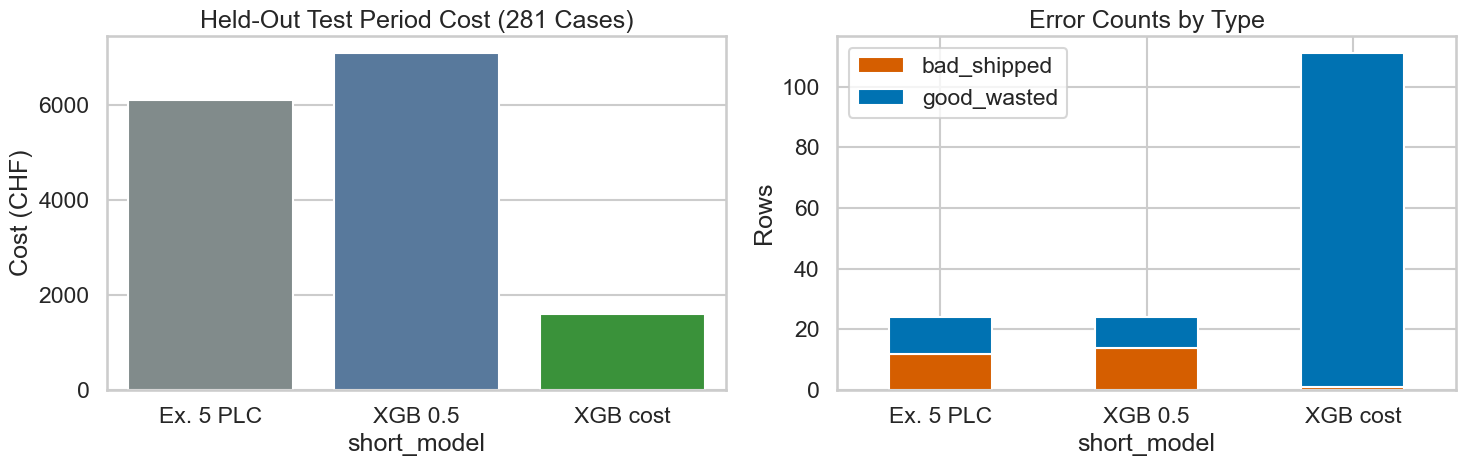

**Exercise 5 PLC rule**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),133,12
Actual GOOD (1),12,124


**Exercise 7 XGBoost, default threshold**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),131,14
Actual GOOD (1),10,126


**Exercise 7 XGBoost, cost-optimized**

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),144,1
Actual GOOD (1),110,26


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_df = comparison.copy()
plot_df["short_model"] = ["Ex. 5 PLC", "XGB 0.5", "XGB cost"]
sns.barplot(data=plot_df, x="short_model", y="cost_chf", ax=axes[0], palette=["#7f8c8d", "#4c78a8", "#2ca02c"])
axes[0].set_title("Held-Out Test Period Cost (281 Cases)")
axes[0].set_ylabel("Cost (CHF)")
err = plot_df.set_index("short_model")[["bad_shipped", "good_wasted"]]
err.plot(kind="bar", stacked=True, ax=axes[1], color=["#d55e00", "#0072b2"])
axes[1].set_title("Error Counts by Type")
axes[1].set_ylabel("Rows")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

for name, pred in [("Exercise 5 PLC rule", y_pred_plc), ("Exercise 7 XGBoost, default threshold", y_pred_xgb_default), ("Exercise 7 XGBoost, cost-optimized", y_pred_xgb_cost)]:
    display(Markdown(f"**{name}**"))
    display(confusion_frame(y_test, pred))


## 4. Feature Importance in Context

XGBoost feature importance is not a causal explanation. It tells management which signals the model used most often to reduce classification error. High-gain features deserve monitoring because a shift in those features can destabilize the model, as Exercise 9 later demonstrates.


,feature,gain,business_context
0,feature_33,46.904831,Raw SORTEX signal; monitor for drift because t...
1,feature_5,43.642307,Also part of the simple PLC rule; important fo...
2,feature_9,24.032240,Raw SORTEX signal; monitor for drift because t...
3,feature_7,9.081707,Raw SORTEX signal; monitor for drift because t...
4,feature_10,7.237677,Raw SORTEX signal; monitor for drift because t...
5,feature_2,4.565577,Also part of the simple PLC rule; important fo...
6,feature_31,3.976698,Raw SORTEX signal; monitor for drift because t...
7,Urs_Rhythm_Index,3.577006,Engineered operator-trust feature: recent proc...
8,feature_4,3.340303,Raw SORTEX signal; monitor for drift because t...
9,feature_3,3.201309,Raw SORTEX signal; monitor for drift because t...


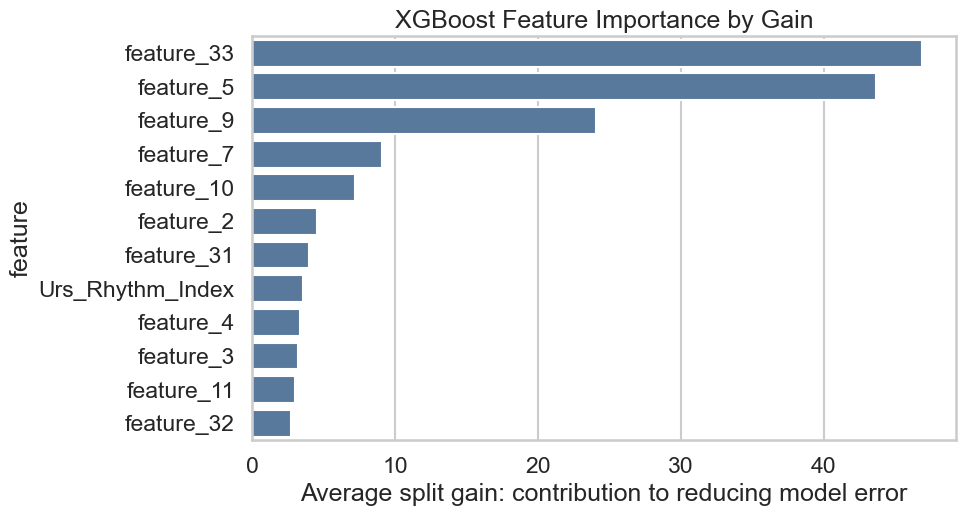

Saved the model handoff for Exercise 9 to `outputs/exercise7_model_artifact.joblib`.

In [7]:
booster = xgb_model.get_booster()
importance = booster.get_score(importance_type="gain")
importance_df = pd.DataFrame([{"feature": key, "gain": value} for key, value in importance.items()])
if not importance_df.empty and importance_df["feature"].str.match(r"f\d+$").all():
    fmap = {f"f{i}": name for i, name in enumerate(model_features)}
    importance_df["feature"] = importance_df["feature"].map(fmap)
importance_df = importance_df.sort_values("gain", ascending=False).reset_index(drop=True)

def feature_context(feature):
    if feature == "Urs_Rhythm_Index":
        return "Engineered operator-trust feature: recent process-signal instability."
    if feature.startswith("Urs_"):
        return "Component of the engineered rhythm/volatility feature."
    if feature in {"feature_1", "feature_2", "feature_5"}:
        return "Also part of the simple PLC rule; important for both simple and unrestricted models."
    if feature.startswith("feature_"):
        return "Raw SORTEX signal; monitor for drift because the physical meaning is undocumented."
    return "Model input."

importance_df["business_context"] = importance_df["feature"].apply(feature_context)
importance_df.to_csv(OUTPUT_DIR / "exercise7_feature_importance.csv", index=False)

display(importance_df.head(15))
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=importance_df.head(12), y="feature", x="gain", ax=ax, color="#4c78a8")
ax.set_title("XGBoost Feature Importance by Gain")
ax.set_xlabel("Average split gain: contribution to reducing model error")
plt.tight_layout()
plt.show()

artifact = {"model": xgb_model, "threshold": best_threshold, "feature_columns": model_features, "label_convention": "Manual_Label: 0=BAD, 1=GOOD; raw CSV labels inverted", "costs_chf": {"BAD_to_GOOD": BAD_SHIPPED_COST_CHF, "GOOD_to_BAD": GOOD_WASTED_COST_CHF}}
joblib.dump(artifact, OUTPUT_DIR / "exercise7_model_artifact.joblib")
display(Markdown("Saved the model handoff for Exercise 9 to `outputs/exercise7_model_artifact.joblib`."))


## 5. Final Exercise 7 Answer

The unrestricted model should be judged by CHF impact, not by headline accuracy. The key management question is whether Dave's 25,000 CHF server creates enough avoided classification loss to pay for itself under the observed early-August volume and case mix.

In [8]:
best_row = comparison.loc[comparison["model"].eq("Exercise 7 XGBoost, cost-optimized")].iloc[0]
plc_row = comparison.loc[comparison["model"].eq("Exercise 5 PLC rule")].iloc[0]
server_investment_chf = 25_000
period_savings = plc_row["cost_chf"] - best_row["cost_chf"]
scaled_savings = plc_row["estimated_cost_for_observed_early_august_period_chf"] - best_row["estimated_cost_for_observed_early_august_period_chf"]
net_after_server = scaled_savings - server_investment_chf
saving_per_case = (plc_row["cost_per_1000_cases_chf"] - best_row["cost_per_1000_cases_chf"]) / 1000
payback_cases = server_investment_chf / saving_per_case if saving_per_case > 0 else np.inf
payback_days = payback_cases / (observed_cases / observed_days) if observed_days > 0 and np.isfinite(payback_cases) else np.inf

investment_table = pd.DataFrame([
    {"item": "PLC estimated cost for observed early-August window", "value_chf": plc_row["estimated_cost_for_observed_early_august_period_chf"]},
    {"item": "XGBoost estimated cost for observed early-August window", "value_chf": best_row["estimated_cost_for_observed_early_august_period_chf"]},
    {"item": "Estimated avoided classification loss over that window", "value_chf": scaled_savings},
    {"item": "Dave server investment", "value_chf": server_investment_chf},
    {"item": "Net benefit after server investment", "value_chf": net_after_server},
])
payback_table = pd.DataFrame([
    {"assumption": "Same case mix and volume as the observed early-August master table", "value": f"{observed_cases:,} cases across {observed_days} production days"},
    {"assumption": "Savings per processed case vs. PLC", "value": f"{saving_per_case:.2f} CHF/case"},
    {"assumption": "Estimated payback volume", "value": f"{payback_cases:,.0f} cases"},
    {"assumption": "Estimated payback time at observed throughput", "value": f"{payback_days:.1f} production days"},
])

display(investment_table)
display(payback_table)
display(Markdown(
    f"On the **281-case held-out test period**, the cost-optimized unrestricted model saves **{period_savings:,.0f} CHF** versus the PLC rule. "
    f"Scaled to the observed **{observed_cases:,}-case early-August production window ({observed_days} production days)**, this corresponds to about **{scaled_savings:,.0f} CHF** lower classification cost. "
    f"After Dave's **25,000 CHF** server investment, the estimated net benefit for that observed window is **{net_after_server:,.0f} CHF** under the same case-mix assumption. "
    "This investment case is conditional on active drift monitoring, because Exercise 9 shows the same conservative threshold can become wasteful under the heatwave regime."
))

,item,value_chf
0,PLC estimated cost for observed early-August w...,43689.395018
1,XGBoost estimated cost for observed early-Augu...,11422.064057
2,Estimated avoided classification loss over tha...,32267.330961
3,Dave server investment,25000.000000
4,Net benefit after server investment,7267.330961


,assumption,value
0,Same case mix and volume as the observed early...,"2,006 cases across 5 production days"
1,Savings per processed case vs. PLC,16.09 CHF/case
2,Estimated payback volume,"1,554 cases"
3,Estimated payback time at observed throughput,3.9 production days


On the **281-case held-out test period**, the cost-optimized unrestricted model saves **4,520 CHF** versus the PLC rule. Scaled to the observed **2,006-case early-August production window (5 production days)**, this corresponds to about **32,267 CHF** lower classification cost. After Dave's **25,000 CHF** server investment, the estimated net benefit for that observed window is **7,267 CHF** under the same case-mix assumption. This investment case is conditional on active drift monitoring, because Exercise 9 shows the same conservative threshold can become wasteful under the heatwave regime.